In [2]:
# ==============================================================================
# CELL 1: ROBUST DATASET SCANNER & CSV BUILDER
# ==============================================================================
import os
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

CSV_OUT = "/kaggle/working/dataset_3_classes.csv"

print("🔍 Scanning /kaggle/working recursively for patient folders containing 'images'...")
patient_dirs = []
for root, dirs, files in os.walk("/kaggle/working"):
    if "images" in dirs:
        p_path = Path(root)
        if (p_path / "images").is_dir():
            patient_dirs.append(p_path)

patient_dirs = sorted(list(set(patient_dirs)))
print(f"✅ Discovered {len(patient_dirs)} patient directories")

if len(patient_dirs) == 0:
    raise RuntimeError(
        "❌ No patient folders with an 'images' subfolder were found! "
        "Please re-run Cell 0 to download and extract the dataset."
    )

records = []
for p_dir in tqdm(patient_dirs, desc="Parsing Patient Metadata"):
    patient_id = p_dir.name
    img_folder = p_dir / "images"
    csv_folder = p_dir / "csv"
    
    slice_images = sorted(list(img_folder.glob("*.png")) + list(img_folder.glob("*.jpg")))
    slice_count = len(slice_images)
    
    normal, infarct, atrophy = 0, 0, 0
    if csv_folder.exists():
        pat_csvs = list(csv_folder.glob("*.csv"))
        if pat_csvs:
            try:
                p_df = pd.read_csv(pat_csvs[0])
                if 'class' in p_df.columns and 'label' in p_df.columns:
                    label_map = dict(zip(p_df['class'], p_df['label']))
                    normal  = int(label_map.get('Normal Study', 0))
                    infarct = int(label_map.get('Infarct / Ischemia', 0))
                    atrophy = int(label_map.get('Cerebral / Cortical Atrophy', 0))
            except Exception:
                pass
    
    if normal == 0 and infarct == 0 and atrophy == 0:
        cat_lower = str(p_dir).lower()
        if "normal" in cat_lower:
            normal = 1
                
    records.append({
        'patient_id': patient_id,
        'folder_path': str(p_dir),
        'image_folder': str(img_folder),
        'slice_count': slice_count,
        'Normal_Study': normal,
        'Infarct_Ischemia': infarct,
        'Cerebral_Atrophy': atrophy,
    })

df_master = pd.DataFrame(records)
df_master.to_csv(CSV_OUT, index=False)

print(f"\n✅ Master dataset CSV successfully generated: {CSV_OUT}")
print(f"   Total Verified Patients: {len(df_master)}")
print(f"   Normal Study:            {df_master['Normal_Study'].sum()}")
print(f"   Infarct / Ischemia:      {df_master['Infarct_Ischemia'].sum()}")
print(f"   Cerebral Atrophy:        {df_master['Cerebral_Atrophy'].sum()}")
display(df_master.head(3))

🔍 Scanning /kaggle/working recursively for patient folders containing 'images'...
✅ Discovered 1819 patient directories


Parsing Patient Metadata:   0%|          | 0/1819 [00:00<?, ?it/s]


✅ Master dataset CSV successfully generated: /kaggle/working/dataset_3_classes.csv
   Total Verified Patients: 1819
   Normal Study:            1048
   Infarct / Ischemia:      668
   Cerebral Atrophy:        570


,patient_id,folder_path,image_folder,slice_count,Normal_Study,Infarct_Ischemia,Cerebral_Atrophy
0,patient_0002,/kaggle/working/Final_preprocessed_V3/disease/...,/kaggle/working/Final_preprocessed_V3/disease/...,14,0,0,1
1,patient_0003,/kaggle/working/Final_preprocessed_V3/disease/...,/kaggle/working/Final_preprocessed_V3/disease/...,14,0,0,1
2,patient_0015,/kaggle/working/Final_preprocessed_V3/disease/...,/kaggle/working/Final_preprocessed_V3/disease/...,14,0,1,1


In [1]:
# ==============================================================================
# CELL 0: ENVIRONMENT SETUP & DATASET DOWNLOAD
# ==============================================================================
!pip install gdown -q

import os, zipfile
import gdown
from pathlib import Path

GDRIVE_FILE_ID = "1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz"
ZIP_PATH = "/kaggle/working/Final_preprocessed_V3.zip"
TARGET_DIR = Path("/kaggle/working/Final_preprocessed_V3")

needs_download = False
if not TARGET_DIR.exists():
    needs_download = True
else:
    sample_images = list(TARGET_DIR.glob("**/images/*.png"))
    if len(sample_images) == 0:
        needs_download = True

if needs_download:
    print("🔄 Downloading Final_preprocessed_V3.zip from Google Drive...")
    gdown.download(f"https://drive.google.com/uc?id={GDRIVE_FILE_ID}", ZIP_PATH, quiet=False)
    
    print("📦 Extracting dataset archive...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall("/kaggle/working")
    
    if os.path.exists(ZIP_PATH):
        os.remove(ZIP_PATH)
        print("🗑️ Removed zip archive to preserve disk space.")
    print("✅ Extraction complete.")
else:
    print(f"✅ Dataset already exists at {TARGET_DIR}")

🔄 Downloading Final_preprocessed_V3.zip from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz
From (redirected): https://drive.google.com/uc?id=1SSZxRtmOY9T4W8VwXPJK8WPwd4sB4tpz&confirm=t&uuid=8006fc0d-a15e-4226-a1a1-8721e7451ca2
To: /kaggle/working/Final_preprocessed_V3.zip
100%|██████████| 696M/696M [00:06<00:00, 106MB/s]  


📦 Extracting dataset archive...
🗑️ Removed zip archive to preserve disk space.
✅ Extraction complete.


In [3]:
%%writefile /kaggle/working/dataset_pipeline.py
import time, copy, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 224
NUM_SLICES = 14

class VolumetricBrainCTDataset(Dataset):
    def __init__(self, dataframe, classes, is_training=False, label_smoothing=0.05):
        self.df = dataframe.reset_index(drop=True)
        self.classes = classes
        self.is_training = is_training
        self.label_smoothing = label_smoothing
        self.normalize = transforms.Normalize(mean=[0.485], std=[0.229])
    
    def __len__(self):
        return len(self.df)
    
    def _sample_affine(self):
        angle = float(np.random.uniform(-10, 10))
        scale = float(np.random.uniform(0.92, 1.08))
        translate = (float(np.random.uniform(-8, 8) / IMG_SIZE), float(np.random.uniform(-8, 8) / IMG_SIZE))
        contrast = float(np.random.uniform(0.90, 1.10))
        brightness = float(np.random.uniform(-0.05, 0.05))
        return angle, scale, translate, contrast, brightness

    def _apply_affine(self, img_t, angle, scale, translate, contrast, brightness):
        theta = torch.zeros(1, 2, 3)
        cos_a = np.cos(np.radians(angle)) * scale
        sin_a = np.sin(np.radians(angle)) * scale
        theta[0, 0, 0] = cos_a
        theta[0, 0, 1] = -sin_a
        theta[0, 0, 2] = translate[0]
        theta[0, 1, 0] = sin_a
        theta[0, 1, 1] = cos_a
        theta[0, 1, 2] = translate[1]
        grid = F.affine_grid(theta, img_t.unsqueeze(0).size(), align_corners=False)
        warped = F.grid_sample(img_t.unsqueeze(0), grid, align_corners=False, mode='bilinear', padding_mode='zeros').squeeze(0)
        return (warped * contrast + brightness).clamp(0, 1)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_folder = Path(row['image_folder'])
        slice_paths = sorted(list(img_folder.glob("*.png")) + list(img_folder.glob("*.jpg")))[:NUM_SLICES]
        while len(slice_paths) < NUM_SLICES:
            slice_paths.append(slice_paths[-1])
        if self.is_training:
            aug_params = self._sample_affine()
        slices = []
        for sp in slice_paths:
            img = Image.open(sp).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            img_t = transforms.ToTensor()(img)
            if self.is_training:
                img_t = self._apply_affine(img_t, *aug_params)
            slices.append(self.normalize(img_t))
        volume = torch.stack(slices, dim=0)
        labels = torch.tensor([row[c] for c in self.classes], dtype=torch.float32)
        if self.is_training and self.label_smoothing > 0:
            labels = labels * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing
        return volume, labels

Writing /kaggle/working/dataset_pipeline.py


In [4]:
# ==============================================================================
# CELL 2.5: REPRODUCIBLE SPLITS & DATALOADERS SETUP
# ==============================================================================
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from dataset_pipeline import VolumetricBrainCTDataset

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Device: {device} ({torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU'})")

CLASSES = ['Normal_Study', 'Infarct_Ischemia', 'Cerebral_Atrophy']
CLASS_NAMES = ['Normal Study', 'Infarct / Ischemia', 'Cerebral Atrophy']
NUM_CLASSES = 3
NUM_SLICES = 14
IMG_SIZE = 224
BATCH_SIZE = 8

CSV_PATH = "/kaggle/working/dataset_3_classes.csv"
if not os.path.exists(CSV_PATH) or os.path.getsize(CSV_PATH) == 0:
    raise FileNotFoundError("❌ dataset_3_classes.csv is missing. Please run Cell 1 first!")

df = pd.read_csv(CSV_PATH)
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)
print(f"📊 Patient Splits: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

train_loader = DataLoader(VolumetricBrainCTDataset(train_df, CLASSES, is_training=True),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(VolumetricBrainCTDataset(val_df, CLASSES, is_training=False),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(VolumetricBrainCTDataset(test_df, CLASSES, is_training=False),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"✅ DataLoaders prepared successfully (Batch Size={BATCH_SIZE})")

🖥️ Device: cuda (Tesla T4)
📊 Patient Splits: Train=1273, Val=273, Test=273
✅ DataLoaders prepared successfully (Batch Size=8)


In [5]:
# ==============================================================================
# CELL 3: RESNET-101 VOLUMETRIC ARCHITECTURE
# ==============================================================================
import gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

# Flush VRAM before building model
gc.collect()
torch.cuda.empty_cache()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_CLASSES = 3
MODEL_NAME = 'resnet101'

class SliceAttention(nn.Module):
    def __init__(self, feature_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        scores = self.net(x)
        weights = F.softmax(scores, dim=1)
        out = (x * weights).sum(dim=1)
        return out, weights.squeeze(-1)

class ResNet101BrainCTClassifier(nn.Module):
    def __init__(self, num_classes=3, pretrained=True, dropout_rate=0.4):
        super().__init__()
        
        # Load torchvision ResNet-101
        weights = models.ResNet101_Weights.DEFAULT if pretrained else None
        resnet = models.resnet101(weights=weights)
        
        # Adapt conv1: 3 channels -> 1 channel grayscale
        orig_conv = resnet.conv1
        new_conv = nn.Conv2d(1, orig_conv.out_channels, kernel_size=orig_conv.kernel_size,
                             stride=orig_conv.stride, padding=orig_conv.padding, bias=orig_conv.bias is not None)
        with torch.no_grad():
            new_conv.weight.copy_(orig_conv.weight.mean(dim=1, keepdim=True))
            if orig_conv.bias is not None:
                new_conv.bias.copy_(orig_conv.bias)
        resnet.conv1 = new_conv
        
        # Stem and stages
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4
        self.avgpool = resnet.avgpool
        
        self.feature_dim = 2048  # ResNet-101 bottleneck feature dimension
        del resnet
        gc.collect()
        
        self.slice_attention = SliceAttention(self.feature_dim)
        
        self.classifier = nn.Sequential(
            nn.LayerNorm(self.feature_dim),
            nn.Dropout(dropout_rate),
            nn.Linear(self.feature_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(256, num_classes)
        )
        self.slice_drop_prob = 0.05

    def extract_slice_features(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.avgpool(x)
        return torch.flatten(x, 1)

    def forward(self, volume):
        B, S, C, H, W = volume.shape
        # Memory-safe sequential slice processing (< 2.8 GB VRAM on T4)
        slice_feats = []
        for s in range(S):
            feat = self.extract_slice_features(volume[:, s])
            slice_feats.append(feat)
        slice_feats = torch.stack(slice_feats, dim=1)
        
        if self.training and np.random.random() < self.slice_drop_prob:
            drop_idx = np.random.randint(0, S)
            slice_feats[:, drop_idx] = 0.0
            
        patient_feat, attn_weights = self.slice_attention(slice_feats)
        logits = self.classifier(patient_feat)
        return logits, attn_weights

model = ResNet101BrainCTClassifier(num_classes=NUM_CLASSES, pretrained=True).to(device)
print(f"✅ {MODEL_NAME.upper()} Architecture Initialized (TorchVision Native)")
print(f"   Backbone Feature Dim: {model.feature_dim} (ResNet-101 Bottleneck)")
print(f"   Total Parameters:     {sum(p.numel() for p in model.parameters()):,}")
print(f"   Current VRAM Used:    {torch.cuda.memory_allocated()/1e9:.2f} GB / {torch.cuda.get_device_properties(0).total_memory/1e9:.2f} GB")

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 236MB/s]  


✅ RESNET101 Architecture Initialized (TorchVision Native)
   Backbone Feature Dim: 2048 (ResNet-101 Bottleneck)
   Total Parameters:     43,285,700
   Current VRAM Used:    0.17 GB / 15.64 GB


In [6]:
# ==============================================================================
# CELL 4: TWO-STAGE TRANSFER LEARNING TRAINING LOOP
# ==============================================================================
import os, gc, time, copy
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import roc_auc_score, f1_score

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

exp_dir = Path(f"/kaggle/working/{MODEL_NAME}_BrainCT_Experiment")
exp_dir.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = exp_dir / f"best_{MODEL_NAME}_brain_ct.pth"

# Positive class weights to balance prevalence
pos_counts = train_df[['Normal_Study', 'Infarct_Ischemia', 'Cerebral_Atrophy']].sum().values
neg_counts = len(train_df) - pos_counts
pos_weight = torch.tensor(neg_counts / np.maximum(pos_counts, 1), dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Hyperparameters
STAGE1_EPOCHS = 5   # Warmup with backbone frozen
STAGE2_EPOCHS = 20  # Full fine-tuning
TOTAL_EPOCHS = STAGE1_EPOCHS + STAGE2_EPOCHS

backbone_modules = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3, model.layer4]

# Stage 1: Freeze Backbone
for module in backbone_modules:
    for param in module.parameters():
        param.requires_grad = False
for param in model.slice_attention.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = AdamW([
    {'params': model.slice_attention.parameters(), 'lr': 1e-3, 'weight_decay': 1e-2},
    {'params': model.classifier.parameters(),      'lr': 1e-3, 'weight_decay': 1e-2}
])
scheduler = CosineAnnealingLR(optimizer, T_max=STAGE1_EPOCHS, eta_min=1e-6)

history = {
    'train_loss': [], 'val_loss': [],
    'val_macro_auc': [], 'val_macro_f1': []
}

best_val_loss = float('inf')
best_val_f1 = 0.0

print(f"\n🚀 Commencing Training: {MODEL_NAME.upper()}")
print(f"   Stage 1 (Epochs 1-{STAGE1_EPOCHS}): Warmup with Backbone Frozen")
print(f"   Stage 2 (Epochs {STAGE1_EPOCHS+1}-{TOTAL_EPOCHS}): End-to-End Fine-Tuning")
print("=" * 80)

for epoch in range(1, TOTAL_EPOCHS + 1):
    epoch_start = time.time()
    
    # Transition to Stage 2: Unfreeze Backbone
    if epoch == STAGE1_EPOCHS + 1:
        print("\n🔓 Unfreezing Backbone for Stage 2 Fine-Tuning...")
        gc.collect()
        torch.cuda.empty_cache()
        backbone_params = []
        for module in backbone_modules:
            for param in module.parameters():
                param.requires_grad = True
                backbone_params.append(param)
                
        optimizer = AdamW([
            {'params': backbone_params,                   'lr': 5e-5, 'weight_decay': 1e-4},
            {'params': model.slice_attention.parameters(), 'lr': 2e-4, 'weight_decay': 1e-2},
            {'params': model.classifier.parameters(),      'lr': 2e-4, 'weight_decay': 1e-2}
        ])
        scheduler = CosineAnnealingLR(optimizer, T_max=STAGE2_EPOCHS, eta_min=1e-6)

    # ── Train Step ────────────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    for volumes, labels in train_loader:
        volumes = volumes.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        optimizer.zero_grad()
        logits, _ = model(volumes)
        loss = criterion(logits, labels)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        train_loss += loss.item() * len(labels)
        
    scheduler.step()
    train_loss /= len(train_df)

    # ── Validation Step ───────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    val_preds, val_targets = [], []
    with torch.no_grad():
        for volumes, labels in val_loader:
            volumes = volumes.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            
            logits, _ = model(volumes)
            loss = criterion(logits, labels)
            val_loss += loss.item() * len(labels)
            
            probs = torch.sigmoid(logits)
            val_preds.append(probs.cpu().numpy())
            val_targets.append(labels.cpu().numpy())

    val_loss /= len(val_df)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)

    try:
        val_auc = float(np.mean([roc_auc_score(val_targets[:, c], val_preds[:, c]) for c in range(3)]))
    except Exception:
        val_auc = 0.5
    val_f1 = float(np.mean([f1_score(val_targets[:, c], (val_preds[:, c] >= 0.5).astype(int), zero_division=0) for c in range(3)]))

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_macro_auc'].append(val_auc)
    history['val_macro_f1'].append(val_f1)

    elapsed = time.time() - epoch_start
    is_best = val_loss < best_val_loss
    if is_best:
        best_val_loss = val_loss
        best_val_f1 = val_f1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_loss,
            'val_auc': val_auc,
            'val_f1': val_f1
        }, BEST_MODEL_PATH)
        star = " ⭐ (Best Model Saved)"
    else:
        star = ""

    print(f"Epoch [{epoch:02d}/{TOTAL_EPOCHS:02d}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
          f"Val AUC: {val_auc:.4f} | Val F1: {val_f1*100:.2f}%{star}")

print(f"\n✅ Training Complete. Best Checkpoint saved at: {BEST_MODEL_PATH}")


🚀 Commencing Training: RESNET101
   Stage 1 (Epochs 1-5): Warmup with Backbone Frozen
   Stage 2 (Epochs 6-25): End-to-End Fine-Tuning
Epoch [01/25] (159.5s) | Train Loss: 0.6518 | Val Loss: 0.5264 | Val AUC: 0.8883 | Val F1: 74.83% ⭐ (Best Model Saved)
Epoch [02/25] (158.4s) | Train Loss: 0.5697 | Val Loss: 0.7283 | Val AUC: 0.7639 | Val F1: 69.81%
Epoch [03/25] (158.5s) | Train Loss: 0.5428 | Val Loss: 0.5644 | Val AUC: 0.8742 | Val F1: 71.83%
Epoch [04/25] (158.5s) | Train Loss: 0.5100 | Val Loss: 0.5710 | Val AUC: 0.9145 | Val F1: 72.94%
Epoch [05/25] (158.4s) | Train Loss: 0.4969 | Val Loss: 0.5665 | Val AUC: 0.9184 | Val F1: 72.07%

🔓 Unfreezing Backbone for Stage 2 Fine-Tuning...
Epoch [06/25] (429.4s) | Train Loss: 0.5567 | Val Loss: 0.4813 | Val AUC: 0.9364 | Val F1: 77.72% ⭐ (Best Model Saved)
Epoch [07/25] (429.7s) | Train Loss: 0.5014 | Val Loss: 0.3521 | Val AUC: 0.9478 | Val F1: 85.47% ⭐ (Best Model Saved)
Epoch [08/25] (429.6s) | Train Loss: 0.4982 | Val Loss: 0.3965 | 

In [7]:
# ==============================================================================
# CELL 5: VALIDATION-CALIBRATED THRESHOLDS & TEST SET EVALUATION
# ==============================================================================
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, 
                             recall_score, accuracy_score, confusion_matrix)

# Load Best Checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"✅ Loaded checkpoint from Epoch {checkpoint['epoch']} (Val Loss: {checkpoint['val_loss']:.4f})")

# 1. Collect Validation Predictions for Calibration
val_probs, val_labels = [], []
with torch.no_grad():
    for volumes, labels in val_loader:
        volumes = volumes.to(device)
        logits, _ = model(volumes)
        val_probs.append(torch.sigmoid(logits).cpu().numpy())
        val_labels.append(labels.numpy())
val_probs = np.concatenate(val_probs, axis=0)
val_labels = np.concatenate(val_labels, axis=0)

# 2. Derive Optimal Operating Thresholds on Validation Set
optimal_thresholds = []
print("\n📐 Validation Threshold Optimization (Maximizing F1):")
for c in range(3):
    best_th = 0.5
    best_f1 = -1.0
    for th in np.arange(0.10, 0.90, 0.02):
        f1 = f1_score(val_labels[:, c], (val_probs[:, c] >= th).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_th = float(th)
    optimal_thresholds.append(best_th)
    print(f"   [{CLASS_NAMES[c]}]: Optimal θ = {best_th:.2f} (Val F1: {best_f1*100:.2f}%)")

# 3. Collect Test Predictions
test_probs, test_labels = [], []
with torch.no_grad():
    for volumes, labels in test_loader:
        volumes = volumes.to(device)
        logits, _ = model(volumes)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())
        test_labels.append(labels.numpy())
test_probs = np.concatenate(test_probs, axis=0)
test_labels = np.concatenate(test_labels, axis=0)

# 4. Compute Test Metrics
results = []
for c in range(3):
    th = optimal_thresholds[c]
    preds = (test_probs[:, c] >= th).astype(int)
    auc = roc_auc_score(test_labels[:, c], test_probs[:, c])
    prec = precision_score(test_labels[:, c], preds, zero_division=0)
    rec = recall_score(test_labels[:, c], preds, zero_division=0)
    f1 = f1_score(test_labels[:, c], preds, zero_division=0)
    acc = accuracy_score(test_labels[:, c], preds)
    
    results.append({
        'Class': CLASS_NAMES[c],
        'Optimal Threshold': round(th, 2),
        'ROC-AUC': round(auc, 4),
        'Sensitivity (Recall)': f"{rec*100:.2f}%",
        'Precision': f"{prec*100:.2f}%",
        'F1-Score': f"{f1*100:.2f}%",
        'Accuracy': f"{acc*100:.2f}%"
    })

res_df = pd.DataFrame(results)
macro_auc = float(np.mean([float(r['ROC-AUC']) for r in results]))
macro_f1  = float(np.mean([float(r['F1-Score'].replace('%', '')) for r in results]))
macro_sens = float(np.mean([float(r['Sensitivity (Recall)'].replace('%', '')) for r in results]))
macro_prec = float(np.mean([float(r['Precision'].replace('%', '')) for r in results]))

summary_row = pd.DataFrame([{
    'Class': 'MACRO AVERAGE',
    'Optimal Threshold': '-',
    'ROC-AUC': round(macro_auc, 4),
    'Sensitivity (Recall)': f"{macro_sens:.2f}%",
    'Precision': f"{macro_prec:.2f}%",
    'F1-Score': f"{macro_f1:.2f}%",
    'Accuracy': '-'
}])
final_report = pd.concat([res_df, summary_row], ignore_index=True)
display(final_report)

final_report.to_csv(exp_dir / f"{MODEL_NAME}_test_evaluation_metrics.csv", index=False)

✅ Loaded checkpoint from Epoch 7 (Val Loss: 0.3521)

📐 Validation Threshold Optimization (Maximizing F1):
   [Normal Study]: Optimal θ = 0.22 (Val F1: 90.91%)
   [Infarct / Ischemia]: Optimal θ = 0.54 (Val F1: 84.68%)
   [Cerebral Atrophy]: Optimal θ = 0.66 (Val F1: 85.41%)


,Class,Optimal Threshold,ROC-AUC,Sensitivity (Recall),Precision,F1-Score,Accuracy
0,Normal Study,0.22,0.9398,95.51%,81.42%,87.91%,84.98%
1,Infarct / Ischemia,0.54,0.9212,83.16%,76.70%,79.80%,85.35%
2,Cerebral Atrophy,0.66,0.9395,78.89%,79.78%,79.33%,86.45%
3,MACRO AVERAGE,-,0.9335,85.85%,79.30%,82.35%,-


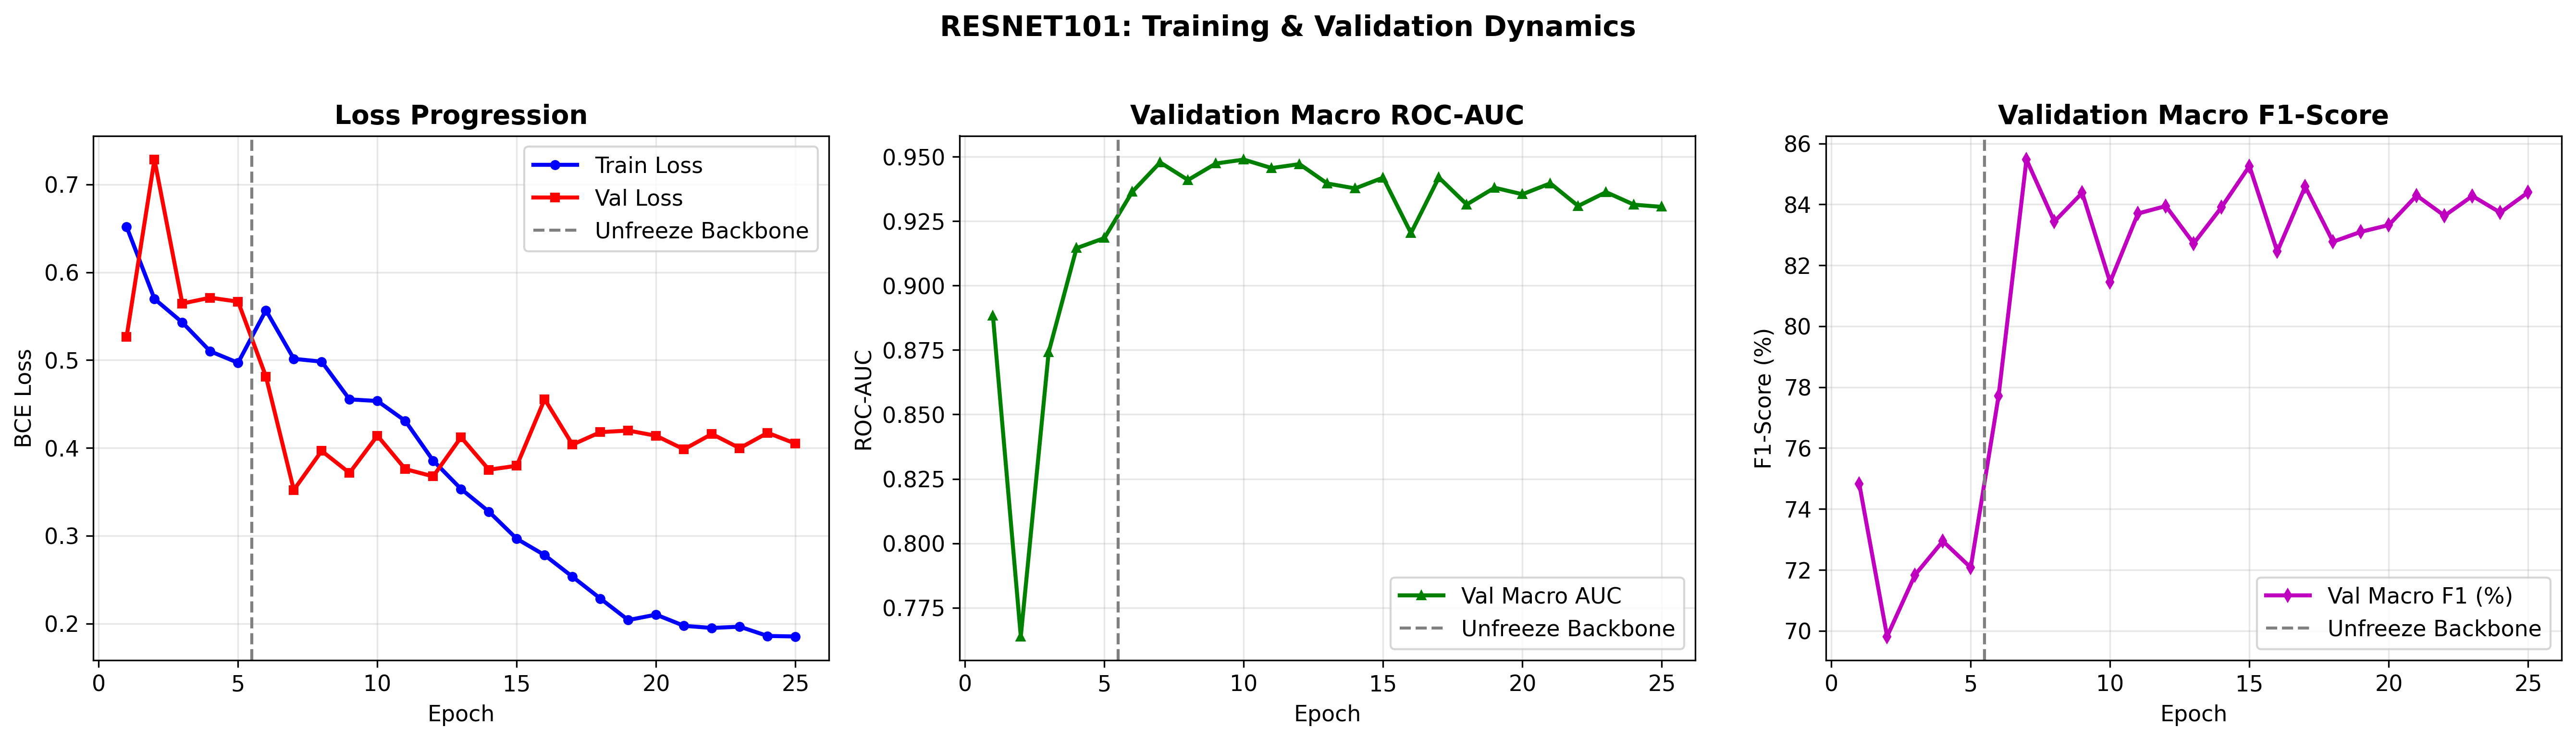

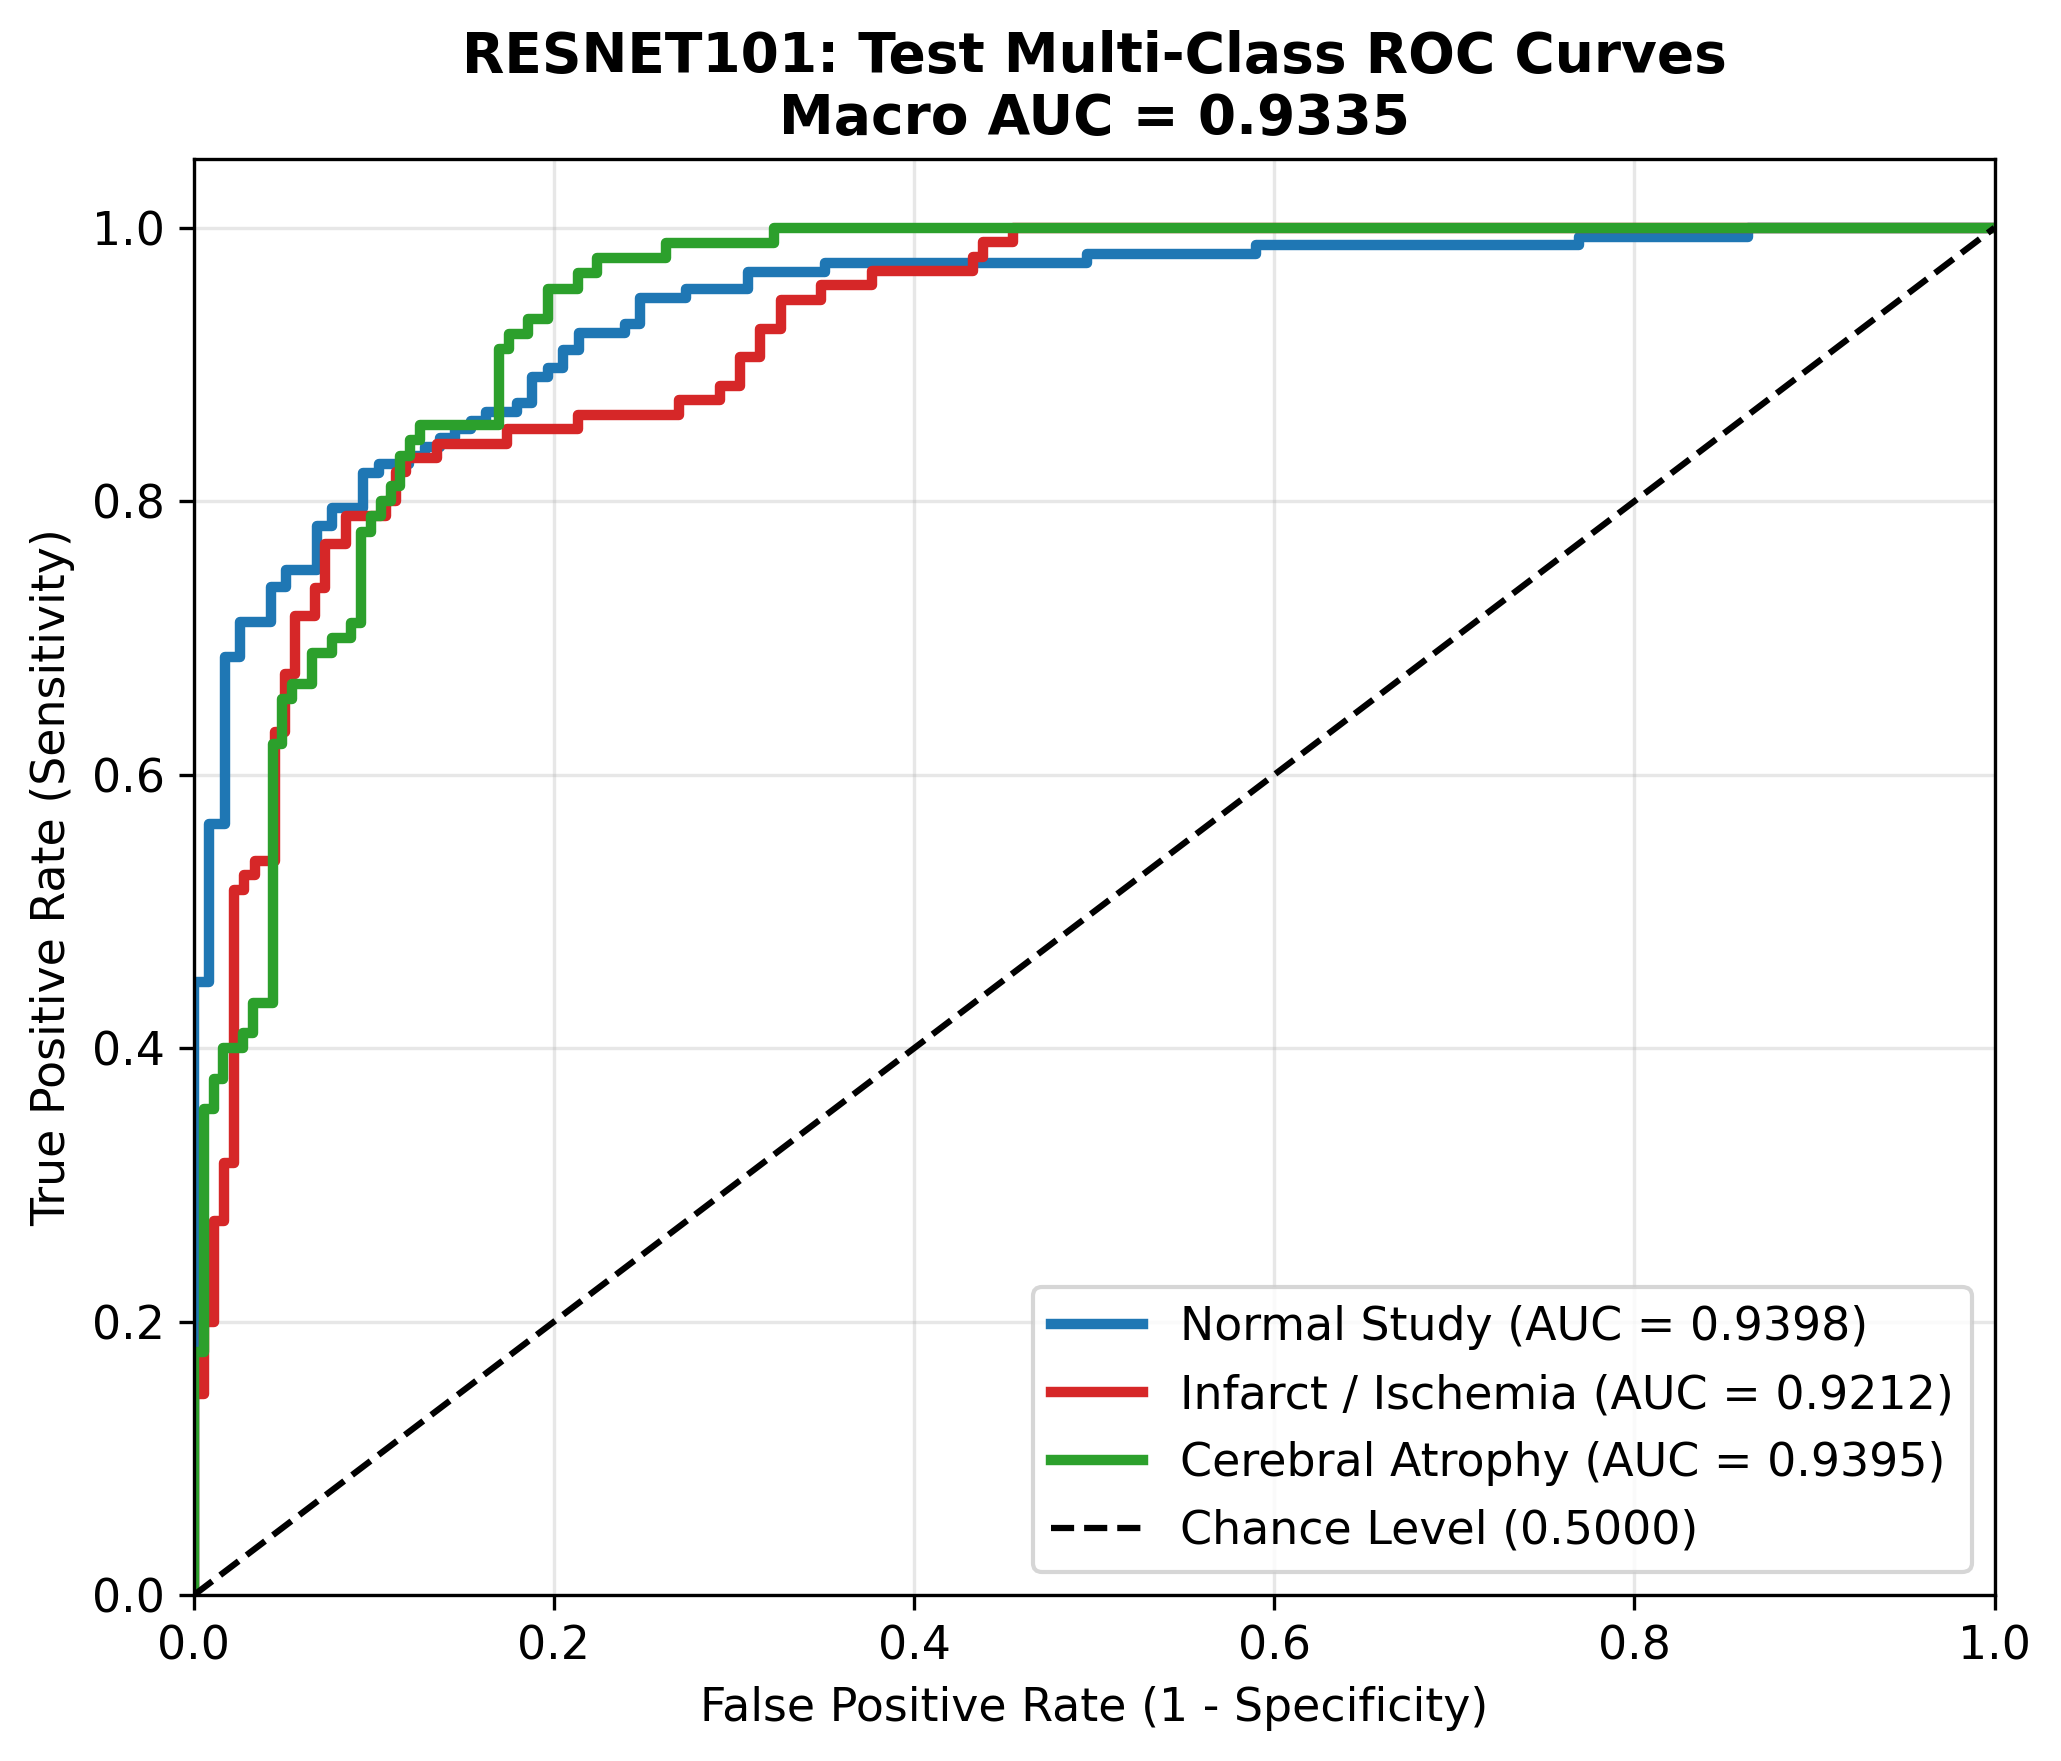

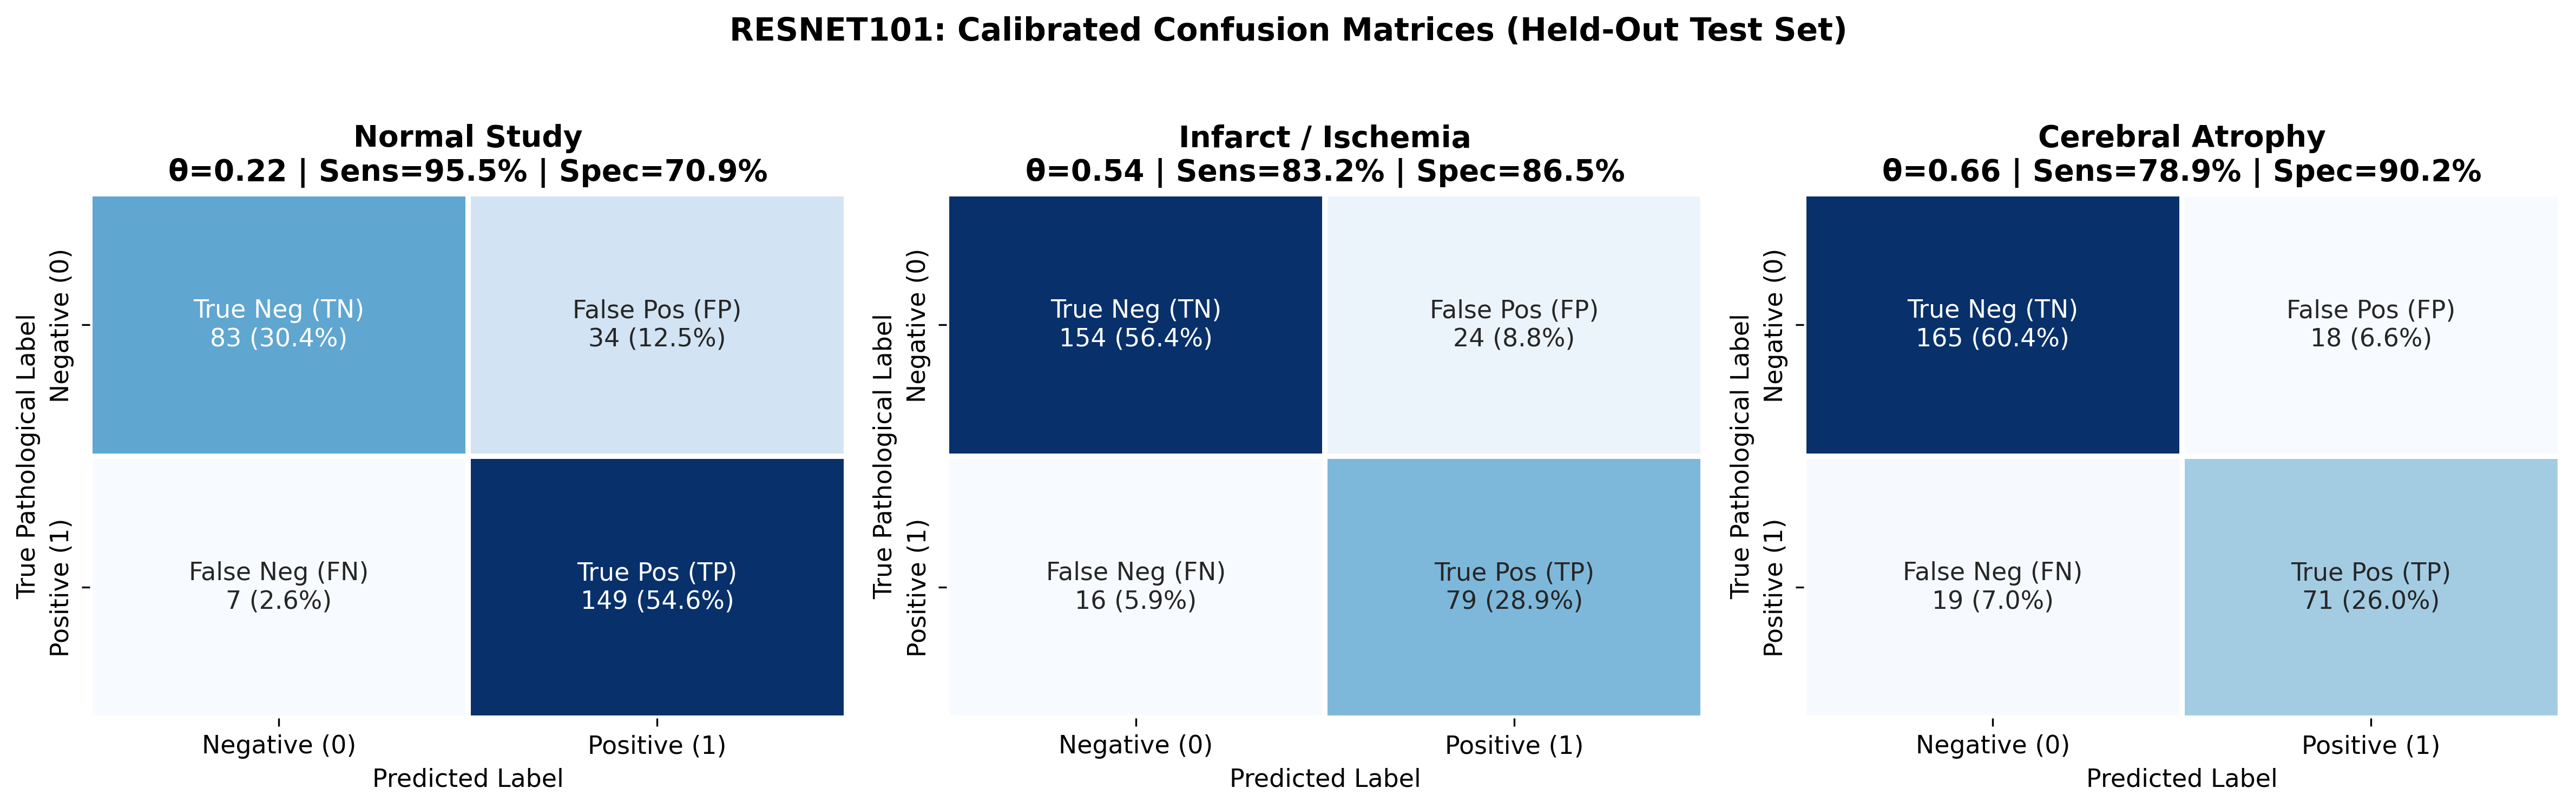

✅ All publication figures saved to: /kaggle/working/resnet101_BrainCT_Experiment


In [8]:
# ==============================================================================
# CELL 6: PUBLICATION-QUALITY 300 DPI VISUALIZATION SUITE
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix

plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# ── Fig 1: Training & Validation Curves ───────────────────────────────────────
epochs_arr = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=300)

axes[0].plot(epochs_arr, history['train_loss'], 'b-o', label='Train Loss', lw=2, markersize=4)
axes[0].plot(epochs_arr, history['val_loss'], 'r-s', label='Val Loss', lw=2, markersize=4)
axes[0].axvline(STAGE1_EPOCHS + 0.5, color='gray', linestyle='--', label='Unfreeze Backbone')
axes[0].set_title('Loss Progression', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_arr, history['val_macro_auc'], 'g-^', label='Val Macro AUC', lw=2, markersize=4)
axes[1].axvline(STAGE1_EPOCHS + 0.5, color='gray', linestyle='--', label='Unfreeze Backbone')
axes[1].set_title('Validation Macro ROC-AUC', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ROC-AUC')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].plot(epochs_arr, [f * 100 for f in history['val_macro_f1']], 'm-d', label='Val Macro F1 (%)', lw=2, markersize=4)
axes[2].axvline(STAGE1_EPOCHS + 0.5, color='gray', linestyle='--', label='Unfreeze Backbone')
axes[2].set_title('Validation Macro F1-Score', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1-Score (%)')
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.suptitle(f"{MODEL_NAME.upper()}: Training & Validation Dynamics", y=1.02, fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_training_curves.png", bbox_inches='tight')
plt.show()

# ── Fig 2: Multi-Class ROC Curves ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6), dpi=300)
colors = ['#1f77b4', '#d62728', '#2ca02c']

for c in range(3):
    fpr, tpr, _ = roc_curve(test_labels[:, c], test_probs[:, c])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[c], lw=2.5, label=f"{CLASS_NAMES[c]} (AUC = {roc_auc:.4f})")

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Chance Level (0.5000)')
ax.set_title(f"{MODEL_NAME.upper()}: Test Multi-Class ROC Curves\nMacro AUC = {macro_auc:.4f}", fontweight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_roc_curves.png", bbox_inches='tight')
plt.show()

# ── Fig 3: Calibrated 2x2 Confusion Matrices ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=300)
cmap = sns.color_palette("Blues", as_cmap=True)

for c in range(3):
    th = optimal_thresholds[c]
    preds = (test_probs[:, c] >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(test_labels[:, c], preds, labels=[0, 1]).ravel()
    tot = tn + fp + fn + tp
    cm = np.array([[tn, fp], [fn, tp]])
    
    annot = np.array([
        [f"True Neg (TN)\n{tn} ({tn/tot*100:.1f}%)", f"False Pos (FP)\n{fp} ({fp/tot*100:.1f}%)"],
        [f"False Neg (FN)\n{fn} ({fn/tot*100:.1f}%)", f"True Pos (TP)\n{tp} ({tp/tot*100:.1f}%)"]
    ])
    
    sns.heatmap(cm, annot=annot, fmt='', cmap=cmap, cbar=False, ax=axes[c],
                xticklabels=['Negative (0)', 'Positive (1)'],
                yticklabels=['Negative (0)', 'Positive (1)'],
                linewidths=2, linecolor='white')
    axes[c].set_title(f"{CLASS_NAMES[c]}\nθ={th:.2f} | Sens={tp/max(tp+fn,1):.1%} | Spec={tn/max(tn+fp,1):.1%}", fontweight='bold')
    axes[c].set_xlabel('Predicted Label')
    axes[c].set_ylabel('True Pathological Label')

plt.suptitle(f"{MODEL_NAME.upper()}: Calibrated Confusion Matrices (Held-Out Test Set)", y=1.03, fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(exp_dir / f"{MODEL_NAME}_confusion_matrices.png", bbox_inches='tight')
plt.show()
print(f"✅ All publication figures saved to: {exp_dir}")